# EDA de desarrollo v2

Análisis ejecutado de metadatos de entrenamiento y validación. La reserva no interviene en las tablas. Los intervalos se generaron mediante `scripts/eda_particion_v2.py`; este notebook reproduce y contrasta las salidas agregadas, sin requerir las imágenes originales.

In [1]:
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, SVG
R=Path.cwd().parent
D=R/'resultados_analizados/eda_v2'
s=pd.read_csv(D/'retencion_y_composicion.csv')
assert set(s.particion)=={'train','validation'}
assert s.groupby('particion').recortes.sum().to_dict()=={'train':14539,'validation':2049}
display(s.round(4))

,particion,clase,anotaciones,recortes,retencion,retencion_ic95_inf,retencion_ic95_sup,proporcion,proporcion_ic95_inf,proporcion_ic95_sup
0,train,tumor_nonMitotic,14187,6977,0.4918,0.4764,0.5051,0.4799,0.4222,0.5372
1,train,lymphocyte,9946,4460,0.4484,0.4344,0.4629,0.3068,0.2494,0.3641
2,train,nonTILnonMQ_stromal,6608,3102,0.4694,0.4498,0.4887,0.2134,0.1777,0.2492
3,validation,tumor_nonMitotic,2340,1108,0.4735,0.4315,0.5183,0.5408,0.4317,0.6474
4,validation,lymphocyte,1327,597,0.4499,0.3872,0.4980,0.2914,0.1687,0.4290
5,validation,nonTILnonMQ_stromal,710,344,0.4845,0.4383,0.5303,0.1679,0.1165,0.2203


In [2]:
p=pd.read_csv(D/'recortes_por_paciente.csv')
assert p.groupby('paciente').particion.nunique().max()==1
assert p.groupby('tss').particion.nunique().max()==1
display(p.groupby('particion').recortes.agg(['count','min','median','max']))
display(pd.read_csv(D/'seleccion_por_motivo.csv'))

,count,min,median,max
particion,,,,
train,83,7,121.0,547
validation,21,2,79.0,231


,particion,estado,anotaciones
0,train,caja_fuera_de_imagen,441
1,train,caja_invalida,84
2,train,caja_no_contenida,4
3,train,incluida,14539
4,train,requiere_relleno,15673
5,validation,caja_fuera_de_imagen,56
6,validation,caja_invalida,2
7,validation,caja_no_contenida,4
8,validation,incluida,2049
9,validation,requiere_relleno,2266


{
  "fuente_sha256": "4e1574051a66740c050c3cd66fb11d423f2c57f313a4d71c02f9b2f3a913c77c",
  "alcance": "Solo entrenamiento y validación; metadatos, sin análisis de píxeles ni predicciones de reserva",
  "bootstrap": {
    "repeticiones": 5000,
    "semilla": 4101,
    "unidad": "paciente dentro de cada partición",
    "intervalo": "percentil 95%; razón de totales de los pacientes remuestreados",
    "limitacion": "Condicional a los TSS observados; no estima incertidumbre entre centros ni corrige decisiones históricas"
  },
  "pacientes": {
    "train": 83,
    "validation": 21
  },
  "resumen_recortes_por_paciente": {
    "train": {
      "min": 7,
      "mediana": 121.0,
      "max": 547
    },
    "validation": {
      "min": 2,
      "mediana": 79.0,
      "max": 231
    }
  }
}


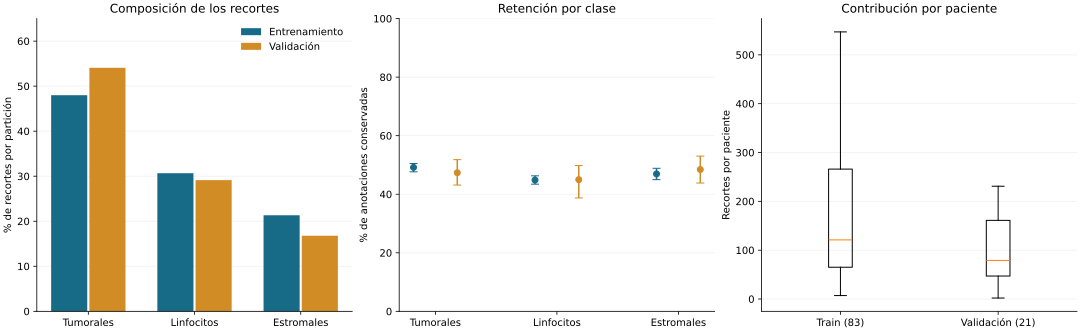

In [3]:
display(SVG(filename=str(R/'book/figuras/eda_desarrollo_v2.svg')))
print(json.dumps(json.loads((D/'metodo.json').read_text()),ensure_ascii=False,indent=2))

La composición y la contribución desigual de los pacientes justifican informar métricas por clase y estimar incertidumbre por paciente. La mayor proporción tumoral en validación no constituye evidencia de un mecanismo biológico: describe la selección disponible. Los resultados no incluyen calidad de píxeles ni desempeño predictivo.